In [1]:

# =====================================================
# HORIZON FINANCIAL GROUP — PROJECT 3
# STEP 1: DATA DISCOVERY AND JOIN READINESS
# =====================================================

from pathlib import Path
import pandas as pd

# Colab stores uploaded files inside /content
data_folder = Path("/content")
csv_files = sorted(data_folder.glob("*.csv"))

print("HORIZON FINANCIAL GROUP — DATA DISCOVERY")
print("=" * 60)
print("CSV files found:", len(csv_files))

assert len(csv_files) == 2, (
    "Please upload exactly two project CSV files."
)

datasets = {}

for file in csv_files:
    df = pd.read_csv(file)
    datasets[file.stem] = df

    print(f"\nDATASET: {file.name}")
    print("-" * 60)
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Column names:", df.columns.tolist())
    print("Missing values:", int(df.isna().sum().sum()))
    print("Duplicate rows:", int(df.duplicated().sum()))

    print("\nData types:")
    print(df.dtypes.to_string())

    print("\nFirst 3 rows:")
    display(df.head(3))

    if "borrower_id" in df.columns:
        print(
            "Unique borrower IDs:",
            df["borrower_id"].nunique()
        )
        print(
            "Missing borrower IDs:",
            df["borrower_id"].isna().sum()
        )

print("\nDATA DISCOVERY COMPLETE")


HORIZON FINANCIAL GROUP — DATA DISCOVERY
CSV files found: 2

DATASET: borrower_profiles.csv
------------------------------------------------------------
Rows: 500
Columns: 11
Column names: ['borrower_id', 'age', 'state', 'education_level', 'employment_status', 'years_employed', 'annual_income', 'credit_score', 'home_ownership', 'dependents', 'existing_monthly_debt']
Missing values: 0
Duplicate rows: 0

Data types:
borrower_id              object
age                       int64
state                    object
education_level          object
employment_status        object
years_employed            int64
annual_income             int64
credit_score              int64
home_ownership           object
dependents                int64
existing_monthly_debt     int64

First 3 rows:


,borrower_id,age,state,education_level,employment_status,years_employed,annual_income,credit_score,home_ownership,dependents,existing_monthly_debt
0,BRW-0001,62,CT,High School,Self-Employed,6,31020,596,Rent,1,892
1,BRW-0002,24,CO,High School,Full-Time,4,40188,543,Own,2,869
2,BRW-0003,50,NC,Bachelor,Contract,22,41014,611,Mortgage,0,1806


Unique borrower IDs: 500
Missing borrower IDs: 0

DATASET: loan_applications.csv
------------------------------------------------------------
Rows: 601
Columns: 12
Column names: ['loan_id', 'borrower_id', 'application_date', 'loan_purpose', 'loan_amount', 'term_months', 'interest_rate', 'monthly_payment', 'dti_ratio', 'loan_status', 'days_delinquent', 'defaulted']
Missing values: 0
Duplicate rows: 0

Data types:
loan_id              object
borrower_id          object
application_date     object
loan_purpose         object
loan_amount         float64
term_months           int64
interest_rate       float64
monthly_payment     float64
dti_ratio           float64
loan_status          object
days_delinquent       int64
defaulted             int64

First 3 rows:


,loan_id,borrower_id,application_date,loan_purpose,loan_amount,term_months,interest_rate,monthly_payment,dti_ratio,loan_status,days_delinquent,defaulted
0,LN-00001,BRW-0001,2024-01-08,Vacation,16100.0,36,13.05,542.86,55.5,Paid Off,0,0
1,LN-00002,BRW-0001,2024-08-13,Major Purchase,5600.0,48,14.21,153.62,40.4,Default,138,1
2,LN-00003,BRW-0002,2025-06-28,Moving,44700.0,36,12.37,1492.59,70.5,Paid Off,0,0


Unique borrower IDs: 500
Missing borrower IDs: 0

DATA DISCOVERY COMPLETE


DTI DATA QUALITY CHECK
Minimum DTI: 7.6
Maximum DTI: 177.4
DTI values above 100%: 22
Negative DTI values: 0
Missing DTI values: 0
1. LOAN PORTFOLIO SUMMARY
Total loans: 601
Unique borrowers: 500
Defaulted loans: 146
Observed default rate: 24.29%
Management target: 12.00%
Difference: +12.29 percentage points

2. DEFAULTS BY CREDIT SCORE


,credit_bucket,loans,defaults,avg_loan_amount,default_rate_pct
0,520-599,116,57,23481.90,49.14
1,600-649,93,27,19196.77,29.03
2,650-699,75,21,22700.00,28.00
3,700-749,86,14,22344.19,16.28
4,750+,231,27,22414.72,11.69



3. DEFAULTS BY DEBT-TO-INCOME RATIO


,dti_bucket,loans,defaults,avg_loan_amount,default_rate_pct
0,Below 20%,48,8,11718.75,16.67
1,20-29.9%,78,10,17343.59,12.82
2,30-39.9%,107,12,21487.85,11.21
3,40-49.9%,97,23,20071.13,23.71
4,50-59.9%,99,31,20058.59,31.31
5,60%+,172,62,30022.67,36.05



4. LOAN PURPOSE RISK


...


8. NUMERIC ASSOCIATIONS WITH DEFAULT


,pearson_correlation
credit_score,-0.286
interest_rate,0.199
dti_ratio,0.192
existing_monthly_debt,0.083
annual_income,-0.082
loan_amount,0.018
years_employed,-0.007


Interpretation: + means higher values are associated with more defaults; - means fewer defaults.

9. HISTORICAL THRESHOLD SCENARIOS


,screen,eligible_loans,eligible_share_pct,eligible_default_pct,flagged_loans,flagged_default_pct,defaults_flagged_pct
0,Credit score >= 600,485,80.70,18.35,116,49.14,39.04
1,Credit score >= 650,392,65.22,15.82,209,40.19,57.53
2,Credit score >= 700,317,52.75,12.93,284,36.97,71.92
3,DTI < 30%,126,20.97,14.29,475,26.95,87.67
4,DTI < 40%,233,38.77,12.88,368,31.52,79.45
5,DTI < 50%,330,54.91,16.06,271,34.32,63.70
6,Score >= 600 AND DTI < 50%,288,47.92,13.89,313,33.87,72.60
7,Score >= 650 AND DTI < 40%,165,27.45,10.30,436,29.59,88.36
8,Score >= 700 AND DTI < 30%,74,12.31,8.11,527,26.57,95.89


Caution: These scenarios use existing issued loans; they cannot estimate outcomes for rejected applicants.


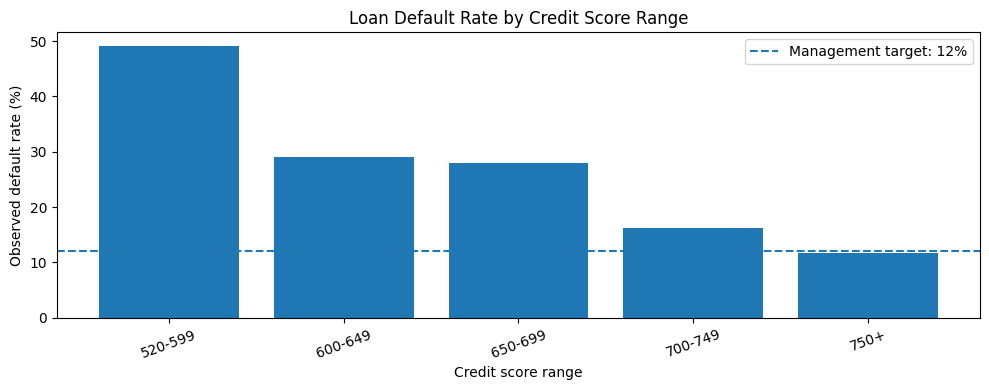

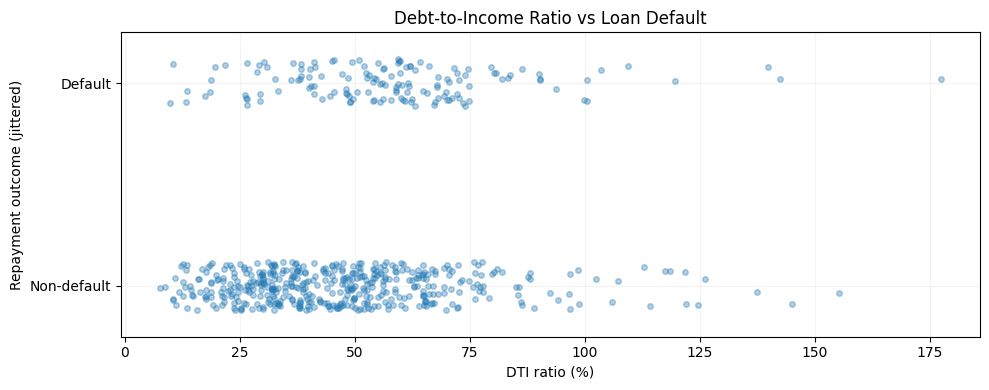

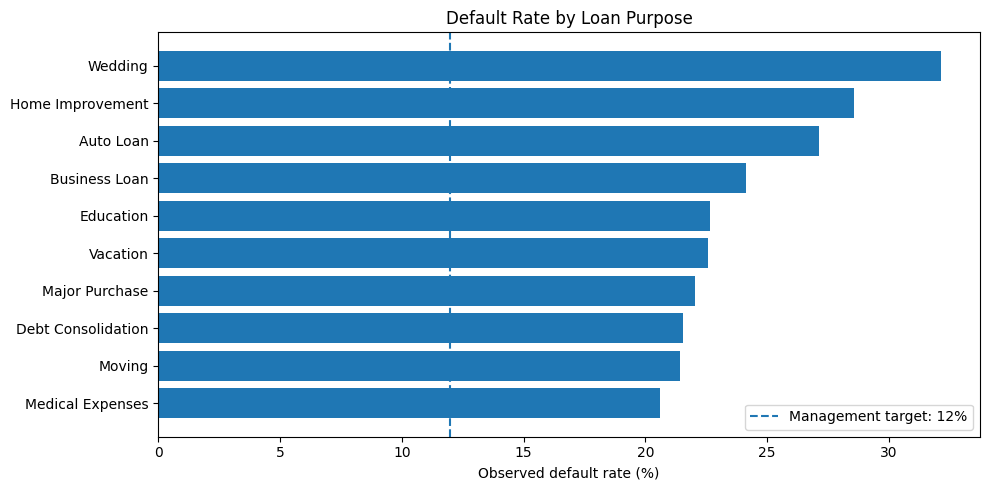


HORIZON FINANCIAL GROUP — VALIDATION STATUS
Borrower-to-loan join: PASS
Loan and default counts: PASS
Segment reconciliation: PASS
Correlation analysis: COMPLETE
Threshold scenarios: COMPLETE
Three required visualizations: COMPLETE
Ready for evidence-based recommendations.


In [3]:

# ============================================================
# HORIZON FINANCIAL GROUP — CREDIT RISK ANALYSIS
# Step 2: Join, Analyze, Visualize, Validate
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# 1. JOIN THE DATASETS
borrowers = datasets["borrower_profiles"].copy()
loans = datasets["loan_applications"].copy()

assert borrowers["borrower_id"].is_unique
assert loans["loan_id"].is_unique
assert loans["defaulted"].isin([0, 1]).all()

df = loans.merge(
    borrowers,
    on="borrower_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

assert (df["_merge"] == "both").all(), (
    "Some loans have no matching borrower profile."
)
df = df.drop(columns="_merge")
df["application_date"] = pd.to_datetime(
    df["application_date"], errors="coerce"
)

assert df["application_date"].notna().all()
assert len(df) == len(loans)

# Validate DTI without incorrectly excluding values above 100%.
# A DTI over 100% means debt payments exceed monthly income.

print("DTI DATA QUALITY CHECK")
print("=" * 50)
print("Minimum DTI:", df["dti_ratio"].min())
print("Maximum DTI:", df["dti_ratio"].max())
print("DTI values above 100%:", (df["dti_ratio"] > 100).sum())
print("Negative DTI values:", (df["dti_ratio"] < 0).sum())
print("Missing DTI values:", df["dti_ratio"].isna().sum())

# Negative or missing DTI would require investigation.
assert df["dti_ratio"].notna().all(), "Missing DTI values detected."
assert (df["dti_ratio"] >= 0).all(), "Negative DTI values detected."

# Function to calculate default statistics by any segment
def default_by(column):
    result = (
        df.groupby(column, observed=True, dropna=False)
        .agg(
            loans=("loan_id", "count"),
            defaults=("defaulted", "sum"),
            avg_loan_amount=("loan_amount", "mean")
        )
        .reset_index()
    )
    result["default_rate_pct"] = (
        result["defaults"] / result["loans"] * 100
    )
    return result

# 2. OVERALL DEFAULT RATE
loan_count = len(df)
default_count = int(df["defaulted"].sum())
default_rate = 100 * df["defaulted"].mean()

TARGET_RATE = 12.0

print("1. LOAN PORTFOLIO SUMMARY")
print("=" * 60)
print(f"Total loans: {loan_count:,}")
print(f"Unique borrowers: {df['borrower_id'].nunique():,}")
print(f"Defaulted loans: {default_count:,}")
print(f"Observed default rate: {default_rate:.2f}%")
print(f"Management target: {TARGET_RATE:.2f}%")
print(f"Difference: {default_rate - TARGET_RATE:+.2f} percentage points")

# 3. CREDIT SCORE SEGMENTS
# Include an additional <520 group so no rows are omitted.
credit_edges = [-np.inf, 520, 600, 650, 700, 750, np.inf]
credit_labels = [
    "Below 520", "520-599", "600-649",
    "650-699", "700-749", "750+"
]

df["credit_bucket"] = pd.cut(
    df["credit_score"],
    bins=credit_edges,
    labels=credit_labels,
    right=False
)

credit_risk = default_by("credit_bucket")

print("\n2. DEFAULTS BY CREDIT SCORE")
display(credit_risk.round(2))

# 4. DTI RANGES
dti_edges = [-np.inf, 20, 30, 40, 50, 60, np.inf]
dti_labels = [
    "Below 20%", "20-29.9%", "30-39.9%",
    "40-49.9%", "50-59.9%", "60%+"
]

df["dti_bucket"] = pd.cut(
    df["dti_ratio"],
    bins=dti_edges,
    labels=dti_labels,
    right=False
)

dti_risk = default_by("dti_bucket")

print("\n3. DEFAULTS BY DEBT-TO-INCOME RATIO")
display(dti_risk.round(2))

# 5. LOAN PURPOSE AND LOAN AMOUNTS
purpose_risk = default_by("loan_purpose")
purpose_risk = purpose_risk.sort_values(
    "default_rate_pct", ascending=False
)

amount_comparison = (
    df.groupby("defaulted")
    .agg(
        loans=("loan_id", "count"),
        avg_loan_amount=("loan_amount", "mean"),
        median_loan_amount=("loan_amount", "median")
    )
    .rename(index={0: "Non-default", 1: "Default"})
)

print("\n4. LOAN PURPOSE RISK")
display(purpose_risk.round(2))

print("\n5. DEFAULT VS NON-DEFAULT LOAN AMOUNTS")
display(amount_comparison.round(2))

# Difference in averages is descriptive, not a
# statistical significance test.
defaulted_avg = df.loc[
    df["defaulted"] == 1, "loan_amount"
].mean()
nondefault_avg = df.loc[
    df["defaulted"] == 0, "loan_amount"
].mean()

print(
    "Difference in mean loan amounts:",
    f"${defaulted_avg - nondefault_avg:,.2f}"
)

# 6. EMPLOYMENT STATUS AND TENURE
employment_risk = default_by("employment_status")
employment_risk = employment_risk.sort_values(
    "default_rate_pct", ascending=False
)

df["employment_tenure"] = np.where(
    df["years_employed"] < 2,
    "Less than 2 years",
    "2+ years"
)

tenure_risk = default_by("employment_tenure")

print("\n6. DEFAULTS BY EMPLOYMENT STATUS")
display(employment_risk.round(2))

print("\n7. EMPLOYMENT TENURE COMPARISON")
display(tenure_risk.round(2))

# 7. NUMERIC CORRELATIONS WITH DEFAULT
# Exclude days_delinquent and loan_status:
# these are repayment outcomes that may leak the answer.
predictors = [
    "credit_score",
    "dti_ratio",
    "annual_income",
    "loan_amount",
    "interest_rate",
    "years_employed",
    "existing_monthly_debt"
]

correlations = (
    df[predictors + ["defaulted"]]
    .corr(numeric_only=True)["defaulted"]
    .drop("defaulted")
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

print("\n8. NUMERIC ASSOCIATIONS WITH DEFAULT")
display(
    correlations.rename("pearson_correlation")
    .to_frame()
    .round(3)
)

print(
    "Interpretation: + means higher values are associated "
    "with more defaults; - means fewer defaults."
)

# 8. EXPLORE CANDIDATE UNDERWRITING THRESHOLDS
# These are historical what-if screens, NOT recommended
# automatic approval or rejection policies.
def evaluate_screen(label, eligible):
    kept = df.loc[eligible]
    flagged = df.loc[~eligible]

    return {
        "screen": label,
        "eligible_loans": len(kept),
        "eligible_share_pct": 100 * len(kept) / len(df),
        "eligible_default_pct": (
            100 * kept["defaulted"].mean()
            if len(kept) else np.nan
        ),
        "flagged_loans": len(flagged),
        "flagged_default_pct": (
            100 * flagged["defaulted"].mean()
            if len(flagged) else np.nan
        ),
        "defaults_flagged_pct": (
            100 * flagged["defaulted"].sum() / default_count
            if default_count else np.nan
        )
    }

screens = []

for minimum_score in [600, 650, 700]:
    screens.append(
        evaluate_screen(
            f"Credit score >= {minimum_score}",
            df["credit_score"] >= minimum_score
        )
    )

for maximum_dti in [30, 40, 50]:
    screens.append(
        evaluate_screen(
            f"DTI < {maximum_dti}%",
            df["dti_ratio"] < maximum_dti
        )
    )

for score, dti in [(600, 50), (650, 40), (700, 30)]:
    screens.append(
        evaluate_screen(
            f"Score >= {score} AND DTI < {dti}%",
            (df["credit_score"] >= score)
            & (df["dti_ratio"] < dti)
        )
    )

threshold_results = pd.DataFrame(screens)

print("\n9. HISTORICAL THRESHOLD SCENARIOS")
display(threshold_results.round(2))
print(
    "Caution: These scenarios use existing issued loans; "
    "they cannot estimate outcomes for rejected applicants."
)

# 9. VISUALIZATION 1 — CREDIT SCORE
plt.figure(figsize=(10, 4))
plt.bar(
    credit_risk["credit_bucket"].astype(str),
    credit_risk["default_rate_pct"]
)
plt.axhline(
    TARGET_RATE, linestyle="--",
    label="Management target: 12%"
)
plt.title("Loan Default Rate by Credit Score Range")
plt.xlabel("Credit score range")
plt.ylabel("Observed default rate (%)")
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

# 10. VISUALIZATION 2 — DTI VS DEFAULT
# Jitter the binary outcome to make overlapping
# observations easier to distinguish visually.
rng = np.random.default_rng(42)
plot_y = (
    df["defaulted"].to_numpy()
    + rng.uniform(-0.12, 0.12, len(df))
)

plt.figure(figsize=(10, 4))
plt.scatter(
    df["dti_ratio"],
    plot_y,
    s=16,
    alpha=0.35
)
plt.yticks([0, 1], ["Non-default", "Default"])
plt.ylim(-0.25, 1.25)
plt.title("Debt-to-Income Ratio vs Loan Default")
plt.xlabel("DTI ratio (%)")
plt.ylabel("Repayment outcome (jittered)")
plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()

# 11. VISUALIZATION 3 — LOAN PURPOSE
purpose_plot = purpose_risk.sort_values("default_rate_pct")

plt.figure(figsize=(10, 5))
plt.barh(
    purpose_plot["loan_purpose"],
    purpose_plot["default_rate_pct"]
)
plt.axvline(
    TARGET_RATE, linestyle="--",
    label="Management target: 12%"
)
plt.title("Default Rate by Loan Purpose")
plt.xlabel("Observed default rate (%)")
plt.legend()
plt.tight_layout()
plt.show()

# 12. FINAL VALIDATION
assert credit_risk["loans"].sum() == len(df)
assert dti_risk["loans"].sum() == len(df)
assert purpose_risk["loans"].sum() == len(df)
assert employment_risk["loans"].sum() == len(df)
assert tenure_risk["loans"].sum() == len(df)
assert credit_risk["defaults"].sum() == default_count
assert dti_risk["defaults"].sum() == default_count
assert df["borrower_id"].notna().all()

print("\nHORIZON FINANCIAL GROUP — VALIDATION STATUS")
print("=" * 60)
print("Borrower-to-loan join: PASS")
print("Loan and default counts: PASS")
print("Segment reconciliation: PASS")
print("Correlation analysis: COMPLETE")
print("Threshold scenarios: COMPLETE")
print("Three required visualizations: COMPLETE")
print("Ready for evidence-based recommendations.")


# Business Recommendations & Underwriting Improvements

## Executive Recommendation

Horizon Financial Group's observed loan default rate is **24.29% (146 of 601 loans)**, exceeding management's 12% target by **12.29 percentage points**.

The analysis identifies credit score, debt-to-income ratio (DTI), and certain borrower subgroups as important areas for further risk evaluation. The company should prioritize improvements to affordability assessment, credit-risk segmentation, application review, and post-origination monitoring.

The recommendations below are based on historical loan outcomes. Proposed thresholds are **candidates for testing and enhanced review—not validated rules for automatically rejecting applicants**.

### Recommendation 1 — Introduce a credit-score-based risk review framework

**Priority: High**

**Evidence:** Borrowers in the 520–599 score range recorded a 49.14% default rate (57 of 116 loans), compared with 11.69% for borrowers with scores of 750 or higher (27 of 231 loans). Credit score had the strongest absolute numeric correlation with default at −0.286.

**Business issue:** The portfolio includes substantial variation in repayment outcomes across credit-score groups. Treating all applicants as equally risky could produce inconsistent underwriting decisions.

**Recommended actions:**
- Establish differentiated review pathways for credit-score segments.
- Trial a score of 650 as a trigger for enhanced affordability verification below that level, rather than as an automatic rejection threshold.
- Evaluate whether additional verified financial information improves risk assessment for lower-score applications.
- Validate the approach using a separate testing period and independent review.

**Historical scenario:** Loans with scores of 650 or higher represented 65.22% of the existing portfolio and had a 15.82% observed default rate. This remains above the 12% goal and is not a forecast of future performance.

**Success indicators:** Default rate by score band, approval rate, manual-review volume, and performance across applicant groups.

### Recommendation 2 — Strengthen DTI validation and affordability reviews

**Priority: High**

**Evidence:** Default rates were 31.31% for loans with DTI between 50% and 59.9%, and 36.05% for loans with DTI of 60% or higher. DTI had a positive correlation with default of 0.192.

**Business issue:** High existing debt obligations may limit a borrower's financial flexibility and repayment capacity.

**Recommended actions:**
- Use DTI of 40% as an initial **enhanced affordability review trigger**, not a universal approval cutoff.
- Verify income, existing debt, and proposed monthly payments when affordability is uncertain.
- Review the **22 loans with recorded DTI above 100%** to confirm the calculation and units. Such values can be mathematically valid, but should be verified.
- Examine whether affordability-review outcomes improve repayment performance without unnecessarily excluding borrowers who would repay successfully.

**Historical scenario:** The group with DTI below 40% contained 233 loans and had a 12.88% default rate. This is close to, but above, management's target.

**Success indicators:** Post-review default rate, verified DTI accuracy, review completion time, and approval-rate changes.

### Recommendation 3 — Pilot a combined credit-score and DTI assessment

**Priority: High**

**Evidence:** The historical group with a credit score of at least 650 **and** DTI below 40% contained 165 loans, with a 10.30% default rate.

**Business opportunity:** Combining independent risk signals may provide a more useful view than relying on either variable alone.

**Recommended actions:**
- Evaluate score and affordability information together in an internal risk-review framework.
- Use the combined screen as a candidate low-risk segment for validation.
- Compare it with the existing underwriting process using out-of-time testing.
- Include verified income, relevant loan characteristics, and repayment capacity in the broader assessment.

**Important trade-off:** This historical screen retained just **27.45% of issued loans**. It flagged 436 loans, including approximately 307 that did not default. Therefore, automatically rejecting everyone outside the screen would risk excluding many historically successful borrowers.

**Success indicators:** Out-of-sample default rate, share of applicants reviewed, approval rate, false-positive rate, and fairness testing results.

### Recommendation 4 — Investigate risk patterns associated with employment tenure

**Priority: Medium**

**Evidence:** The 84 loans associated with fewer than two years of employment had a 34.52% default rate, versus 22.63% for the 517 loans with at least two years of employment.

**Business issue:** Some borrowers with shorter employment histories may have less predictable income, but tenure alone does not reliably measure ability to repay.

**Recommended actions:**
- Investigate whether the subgroup difference persists after accounting for credit score, DTI, income, and borrower overlap.
- Evaluate documentation of income continuity and repayment capacity rather than relying on employment labels alone.
- Avoid automatic exclusions based on employment status or tenure.
- Conduct applicable fair-lending and disparate-impact reviews before changing policy.

**Success indicators:** Repayment outcomes after comparable financial-risk factors are considered, affordability-review quality, and differences in outcomes across applicant groups.

### Recommendation 5 — Review higher-default loan purposes without using them as automatic rejection rules

**Priority: Medium**

**Evidence:** Wedding loans had the highest observed purpose-based default rate at 32.14% (18 of 56), followed by Home Improvement at 28.57% (20 of 70) and Auto Loans at 27.12% (16 of 59).

**Business issue:** Certain loan purposes are associated with higher observed default rates, but these results may reflect differences in borrower characteristics or limited sample sizes.

**Recommended actions:**
- Examine credit score, DTI, income, and loan terms within each purpose category.
- Improve affordability checks and verification where the broader risk profile warrants them.
- Avoid treating loan purpose by itself as evidence of inability to repay.
- Reassess whether differences persist in larger samples.

**Success indicators:** Default rate by purpose after controlling for other factors, sample size, and quality of affordability assessments.

### Recommendation 6 — Improve loan portfolio monitoring and data quality

**Priority: High**

**Evidence:** The analysis found 601 loans across 500 borrowers, indicating repeated borrowing. All supplied fields were complete, but 22 DTI values exceeded 100%.

**Business issue:** Repeated borrowers can make observations statistically dependent, and differences in loan age or repayment status can distort comparisons.

**Recommended actions:**
- Validate the DTI formula and document whether the proposed loan payment is included.
- Track loan origination dates and compare loans at consistent repayment horizons.
- Distinguish fully observed defaults from loans that have not yet had enough time to default.
- Analyze repeated borrowers separately or account for borrower-level clustering.
- Establish routine reporting of delinquency, default, exposure, and repayment outcomes.

**Success indicators:** Data-quality exception rate, consistent reporting definitions, and reliable period-over-period default monitoring.

### Recommendation 7 — Test proposed policies before production deployment

**Priority: High**

**Evidence:** Historical threshold scenarios reveal significant trade-offs between lower observed default rates and smaller eligible groups.

**Recommended actions:**
- Use out-of-time validation, separating earlier originations from later ones.
- Evaluate an interpretable multivariable risk model using only information available at application time.
- Never use `loan_status` or `days_delinquent` as application-time predictors, because they contain subsequent repayment information.
- Account for repeated borrowers when validating models.
- Assess model calibration, approval-rate effects, false positives, stability, and fairness.
- Have credit-risk, compliance, and relevant governance teams review any changes before deployment.

**Success indicators:** Validated default prediction, stable risk estimates, manageable review workload, fair applicant outcomes, and long-term portfolio performance.

---

## Management Action Plan

| Time horizon | Priority action | Success measure |
|---|---|---|
| Immediate | Audit DTI calculations and review portfolio reporting definitions | Data-quality exceptions resolved |
| Immediate | Review score and DTI segmentation | Documented risk-review criteria |
| Next 30 days | Test combined score-and-affordability screening | Out-of-sample risk and approval metrics |
| Next 30–60 days | Investigate employment and loan-purpose patterns | Adjusted subgroup comparisons |
| Next 60–90 days | Evaluate revised underwriting workflow | Pilot outcomes and fairness assessment |
| Ongoing | Monitor default and delinquency trends | Consistent cohort-based reporting |

## Final Business Conclusion

The clearest opportunity for Horizon Financial Group is to improve **how it evaluates credit risk and affordability together**, rather than relying on a single rigid approval rule.

Credit score is the strongest observed numeric indicator, while high DTI is also associated with elevated defaults. Employment tenure and loan purpose warrant further investigation but should not independently drive approval decisions.

The proposed credit-score and DTI review triggers offer practical starting points for validation, not guaranteed solutions. Horizon should pursue lower defaults while monitoring approval access, customer outcomes, and fair-lending requirements.

**Management goal:** Move toward the 12% default-rate target through tested, transparent underwriting improvements—not unvalidated restrictions.

In [4]:

# ============================================================
# HORIZON FINANCIAL GROUP — FINAL DOCUMENTATION
# Creates README.md, requirements.txt, and .gitignore
# ============================================================

from pathlib import Path

# Google Colab's working directory
project_dir = Path.cwd()

# Use results already calculated in the analysis cell.
# If these names are undefined, rerun the analysis cell first.
assert len(df) == 601, "Rerun the analysis cell first."
assert "default_rate" in globals()
assert "threshold_results" in globals()

readme = f"""# Horizon Financial Group — Credit Risk & Loan Default Analysis

## Project Overview

A Python-based credit risk analytics project examining loan
defaults across borrower characteristics, affordability metrics,
employment history, and loan purposes.

**Business goal:** Investigate default drivers and identify
opportunities to improve underwriting and portfolio monitoring.

**Dataset period:** 2024–2025.

## Executive Summary

| KPI | Result |
|---|---:|
| Loans analyzed | {loan_count:,} |
| Unique borrowers | {df["borrower_id"].nunique():,} |
| Defaulted loans | {default_count:,} |
| Observed default rate | {default_rate:.2f}% |
| Management target | {TARGET_RATE:.2f}% |
| Gap above target | {default_rate - TARGET_RATE:.2f} percentage points |

The portfolio's observed default rate exceeds management's target.
Credit score and debt-to-income ratio (DTI) show meaningful
associations with default risk.

## Data Sources

- `borrower_profiles.csv`: 500 borrower profiles, including
  income, employment, credit scores, and existing debt.
- `loan_applications.csv`: 601 loans, including loan amounts,
  purposes, terms, DTI, and repayment outcomes.

The datasets are joined on `borrower_id` using a many-to-one merge.

## Key Findings

### Credit Score

| Score range | Loans | Default rate |
|---|---:|---:|
{chr(10).join(
    f'| {r["credit_bucket"]} | {int(r["loans"])} | {r["default_rate_pct"]:.2f}% |'
    for _, r in credit_risk.iterrows()
)}

### Debt-to-Income Ratio

| DTI range | Loans | Default rate |
|---|---:|---:|
{chr(10).join(
    f'| {r["dti_bucket"]} | {int(r["loans"])} | {r["default_rate_pct"]:.2f}% |'
    for _, r in dti_risk.iterrows()
)}

### Other Findings

- The highest observed loan-purpose default rate was
  Wedding loans at 32.14%.
- Borrowers with less than two years of employment had
  a 34.52% observed default rate, versus 22.63% for
  those with at least two years.
- Defaulted and non-defaulted loans had mean loan amounts
  of $22,570.55 and $22,012.75, respectively.
- Credit score had the strongest absolute measured numeric
  correlation with default (-0.286).
- There were 22 loans with reported DTI greater than 100%;
  these values warrant verification, not automatic deletion.

## Visualizations

The notebook contains:

1. Default rate by credit-score range.
2. DTI versus default status, with outcome jitter.
3. Default rate by loan purpose.

## Business Recommendations

The notebook includes a detailed
**Business Recommendations & Underwriting Improvements**
section with seven recommendations.

Primary priorities:

1. Strengthen credit-risk segmentation and reviews.
2. Improve DTI calculation verification and affordability checks.
3. Test combined credit-score and DTI review criteria.
4. Investigate employment-tenure and loan-purpose patterns.
5. Improve loan-book monitoring and data quality.
6. Validate proposed policies before implementation.

Candidate score and DTI thresholds are exploratory
review triggers, **not automatic rejection rules**.

## Technology

- Python
- pandas
- NumPy
- Matplotlib
- Google Colab / Jupyter Notebook

## Repository Structure

```text
Horizon-Financial-Credit-Risk/
├── Horizon_Credit_Risk_Analysis.ipynb
├── borrower_profiles.csv
├── loan_applications.csv
├── README.md
├── requirements.txt
└── .gitignore
```

## How to Run

1. Download or clone the repository.
2. Install dependencies:

```bash
python -m pip install -r requirements.txt
```

3. Open `Horizon_Credit_Risk_Analysis.ipynb` in Google Colab.
4. Upload both CSV files to the Colab Files panel.
5. Run the notebook cells from top to bottom.

The notebook's discovery cell uses `/content`, the normal
Colab upload directory. When running in local Jupyter,
change this path to the folder containing the CSV files.

**Colab note:** Files uploaded to session storage are temporary.
Re-upload the CSVs when the Colab runtime resets.

## Methodology & Limitations

- Results describe the supplied historical loan portfolio.
- Multiple loans can belong to the same borrower.
- Default rates may depend on loan age and observation period.
- Correlations do not prove that variables cause defaults.
- Interest rates can reflect existing lender risk assessments.
- A historical underwriting screen cannot predict the outcome
  of loans the company never approved.
- Threshold scenarios were not independently validated.
- No formal statistical significance test has been conducted
  on differences between subgroups.
- Applicant-level decisions require further model validation,
  compliance review, and applicable fair-lending safeguards.
- Repayment outcomes such as `loan_status` and
  `days_delinquent` should not be used as application-time
  predictors.

## Project Outcome

This project demonstrates data joining, segmentation,
correlation analysis, visualization, scenario testing,
data validation, and evidence-based business recommendations.

The findings are educational and exploratory, not a
production-ready credit-scoring policy.
"""

(project_dir / "README.md").write_text(
    readme, encoding="utf-8"
)

(project_dir / "requirements.txt").write_text(
    "pandas>=2.0,<4.0\n"
    "numpy>=1.24\n"
    "matplotlib>=3.7,<4.0\n",
    encoding="utf-8"
)

(project_dir / ".gitignore").write_text(
    "__pycache__/\n"
    ".ipynb_checkpoints/\n"
    ".DS_Store\n"
    ".venv/\n",
    encoding="utf-8"
)

print("HORIZON FINANCIAL GROUP — DOCUMENTATION")
print("=" * 55)

for filename in ["README.md", "requirements.txt", ".gitignore"]:
    path = project_dir / filename
    assert path.exists()
    print(f"PASS: {filename} ({path.stat().st_size:,} bytes)")

print("\nDocumentation complete — READY FOR GITHUB")


HORIZON FINANCIAL GROUP — DOCUMENTATION
PASS: README.md (4,955 bytes)
PASS: requirements.txt (50 bytes)
PASS: .gitignore (50 bytes)

Documentation complete — READY FOR GITHUB
